# **DSMBC Online Shoppers Intention: Modelling**

Notebook ini melanjutkan `DSMBC_Online_Shoppers_Preprocessing.ipynb`. Tujuannya melatih beberapa model untuk memprediksi `Revenue` (apakah sesi berakhir dengan pembelian), membandingkannya secara adil, dan menjelaskan **mengapa** tiap model dipilih serta **bagaimana hasilnya dinilai**.

**Cara pakai**
1. Jalankan notebook preprocessing sampai selesai. Hasilnya `data_processed.zip` (berisi `train.csv` dan `test.csv`).
2. Buka notebook ini di Colab lalu **Runtime → Run all**. Saat sel pemuat data meminta, unggah `data_processed.zip` (atau `train.csv` dan `test.csv`). Alternatif: taruh folder `data_processed` di Google Drive.
3. Tidak ada pembersihan data lagi. Bila Colab terputus, jalankan **Run all** sekali lagi; pekerjaan yang sudah selesai dilewati (bagian 2).

**Isi notebook**

| Bagian | Isi |
|---|---|
| 1 | Memuat data hasil preprocessing (tanpa membersihkan ulang) |
| 2 | Sistem checkpoint untuk Google Colab |
| 3 | Mengapa model-model ini, jenis masalah, dan ukuran penilaian |
| 4 | Pencarian hiperparameter per model (dengan checkpoint tiap kandidat) |
| 5 | Pelatihan akhir, ensemble, dan pemilihan ambang keputusan |
| 6 | Evaluasi pada data uji: tabel, laporan lengkap, selang kepercayaan, sensitivitas ambang |
| 7 | Uji tanpa `PageValues` dan interpretasi model |
| 8 | Menyimpan hasil dan kesimpulan |

**Aturan yang dijaga di seluruh notebook**
- Data uji **tidak dipakai** untuk memilih model, hiperparameter, maupun ambang. Semua pilihan memakai cross-validation (CV) pada data latih.
- Preprocessing berada **di dalam pipeline**, jadi dipelajari ulang di tiap fold dan tidak ada kebocoran.
- Metrik utama: **PR-AUC** (*average precision*). Hanya 15,6% sesi yang membeli, dan PR-AUC fokus pada kelas pembeli. Ukuran lain dipakai sebagai pendamping (penjelasan di bagian 3.1).

# **1. PERSIAPAN DAN MEMUAT DATA HASIL PREPROCESSING**

Notebook ini **tidak membersihkan data lagi**. Ia memakai dua file dari notebook preprocessing (di dalam `data_processed.zip`):

| File | Isi | Dipakai di sini |
|---|---|---|
| `train.csv` | Data latih: sudah bersih (boolean jadi 0/1, duplikat dibuang) dan sudah dibagi 80/20 | Ya |
| `test.csv` | Data uji dari pembagian yang sama | Ya (hanya untuk penilaian akhir) |
| `preprocessors.joblib` | Preprocessor yang sudah di-fit pada seluruh data latih | Tidak (lihat di bawah) |
| `train_linear.csv`, `train_tree.csv`, dst. | Versi yang sudah ditransformasi | **Jangan dipakai** |

**Mengapa transformasi (`log1p`, scaling, one-hot) tetap ada di dalam pipeline model?** Bila scaling dihitung dari seluruh data latih lebih dulu lalu dipakai di cross-validation, fold validasi ikut mempengaruhi rata-rata dan simpangan baku yang dipakai. Itu kebocoran kecil yang membuat skor CV sedikit terlalu bagus. Notebook preprocessing sudah memperingatkan hal yang sama. Jadi `train.csv` dan `test.csv` dipakai apa adanya, dan transformasinya dipelajari ulang di dalam tiap fold.

Sel pemuat data memeriksa kolom, nilai kosong, duplikat, dan tumpang tindih latih-uji. Bila Anda tidak sengaja mengunggah file hasil transformasi, ia berhenti dengan pesan yang jelas.

In [10]:
import os, sys, json, time, hashlib, warnings, subprocess, zipfile, shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# XGBoost dan LightGBM biasanya sudah ada di Colab; pasang bila belum
for paket in ("xgboost", "lightgbm"):
    try:
        __import__(paket)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paket])

from sklearn.model_selection import (train_test_split, StratifiedKFold, ParameterSampler,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, balanced_accuracy_score, matthews_corrcoef, brier_score_loss,
                             classification_report)
from scipy.stats import loguniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 130)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

# ---------------- Pengaturan yang boleh diubah ----------------
RANDOM_STATE = 42
CV_FOLDS     = 5       # jumlah fold untuk tuning dan prediksi out-of-fold
N_ITER       = 12      # kandidat hiperparameter per model. Naikkan (mis. 30) bila waktu Colab cukup
USE_DRIVE    = True    # True: simpan checkpoint ke Google Drive agar selamat dari disconnect
DRIVE_FOLDER = "DSMBC_checkpoints"

# Data hasil notebook preprocessing (isi data_processed.zip). Ubah DATA_DIR bila folder Anda di tempat lain.
DATA_DIR   = "data_processed"
TRAIN_FILE = "train.csv"
TEST_FILE  = "test.csv"
# ---------------------------------------------------------------

DRIVE_MOUNTED = False
def mount_drive():
    """Mount Google Drive (hanya di Colab). Dipakai untuk membaca data dan menyimpan checkpoint."""
    global DRIVE_MOUNTED
    if DRIVE_MOUNTED or not USE_DRIVE:
        return DRIVE_MOUNTED
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except ImportError:
        print("Bukan Google Colab: Drive tidak dipakai, checkpoint disimpan lokal.")
    except Exception as e:
        print("Drive gagal di-mount, memakai folder lokal (hilang bila runtime direset):", e)
    return DRIVE_MOUNTED

print("Pustaka siap. N_ITER =", N_ITER, "| CV_FOLDS =", CV_FOLDS)

Pustaka siap. N_ITER = 12 | CV_FOLDS = 5


In [11]:
# Muat data HASIL PREPROCESSING (train.csv dan test.csv dari notebook preprocessing). Tidak ada pembersihan ulang di sini.
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
nominal_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
kolom_fitur = num_cols + nominal_cols + ['Month', 'VisitorType', 'Weekend']
target = 'Revenue'
MIN_FREQ = 100

mount_drive()
folder_cari = [DATA_DIR, "data_processed", "/content/data_processed", "/content", ".",
               f"/content/drive/MyDrive/{DRIVE_FOLDER}/data_processed", "/content/drive/MyDrive/data_processed"]

def temukan(nama):
    return next((os.path.join(d, nama) for d in folder_cari if os.path.exists(os.path.join(d, nama))), None)

p_train, p_test = temukan(TRAIN_FILE), temukan(TEST_FILE)
if p_train is None or p_test is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            f"{TRAIN_FILE} / {TEST_FILE} tidak ditemukan. Letakkan folder 'data_processed' (hasil notebook preprocessing) "
            f"di sebelah notebook ini, atau ubah DATA_DIR di sel pengaturan.")
    print("File belum ditemukan. Unggah data_processed.zip (atau train.csv dan test.csv) hasil notebook preprocessing:")
    unggahan = files.upload()
    for nama in list(unggahan):
        if nama.endswith(".zip"):
            with zipfile.ZipFile(nama) as z:
                z.extractall(".")
    os.makedirs("data_processed", exist_ok=True)
    for nama in list(unggahan):
        if nama in (TRAIN_FILE, TEST_FILE):
            shutil.move(nama, os.path.join("data_processed", nama))
    p_train, p_test = temukan(TRAIN_FILE), temukan(TEST_FILE)
    assert p_train and p_test, "train.csv / test.csv masih tidak ditemukan setelah unggah"

def baca_dan_periksa(path, nama):
    d = pd.read_csv(path)
    hilang = [c for c in kolom_fitur + [target] if c not in d.columns]
    if hilang:
        raise ValueError(f"{nama}: kolom {hilang[:4]} tidak ada. Pakai train.csv/test.csv (data bersih SEBELUM transformasi), "
                         f"bukan train_linear.csv atau train_tree.csv.")
    d = d[kolom_fitur + [target]].copy()
    if d.isna().any().any():
        raise ValueError(f"{nama}: ada nilai kosong. Data seharusnya sudah bersih dari notebook preprocessing.")
    d['Weekend'] = d['Weekend'].astype(int)
    d[target] = d[target].astype(int)
    if not set(d[target].unique()) <= {0, 1}:
        raise ValueError(f"{nama}: kolom {target} harus berisi 0/1")
    return d

tr, te = baca_dan_periksa(p_train, "train"), baca_dan_periksa(p_test, "test")
X_train, y_train = tr.drop(columns=target), tr[target]
X_test, y_test = te.drop(columns=target), te[target]

# Pemeriksaan kewajaran: duplikat dan tumpang tindih latih-uji (bocor bila ada)
dup_latih = int(X_train.duplicated().sum())
tumpang = len(X_test.merge(X_train.drop_duplicates(), how="inner", on=kolom_fitur))
DATA_HASH = hashlib.md5(pd.util.hash_pandas_object(tr, index=False).values.tobytes()).hexdigest()[:8]

print("File latih:", p_train, "\nFile uji  :", p_test)
print("Latih:", X_train.shape, "| Uji:", X_test.shape, f"| sidik data (hash): {DATA_HASH}")
print(f"Proporsi pembeli  latih {y_train.mean():.4f} | uji {y_test.mean():.4f}")
print(f"Baris duplikat di data latih: {dup_latih} | baris uji yang identik dengan baris latih: {tumpang}")
if dup_latih or tumpang:
    print("PERINGATAN: ada duplikat atau tumpang tindih. Notebook preprocessing seharusnya membuang duplikat sebelum split; skor uji bisa terlalu optimistis.")
if (len(X_train), len(X_test)) != (9764, 2441):
    print("Catatan: ukuran data berbeda dari referensi notebook preprocessing (9.764 latih / 2.441 uji). Tidak masalah bila datanya memang berbeda.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File latih: /content/drive/MyDrive/data_processed/train.csv 
File uji  : /content/drive/MyDrive/data_processed/test.csv
Latih: (9764, 17) | Uji: (2441, 17) | sidik data (hash): 0f465d07
Proporsi pembeli  latih 0.1563 | uji 0.1565
Baris duplikat di data latih: 0 | baris uji yang identik dengan baris latih: 0


In [12]:
log_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

def make_preprocessor(branch='linear', drop_pagevalues=False):
    """Sama dengan notebook preprocessing.
    linear: log1p + StandardScaler, BounceRates dilepas (untuk Logistic Regression).
    tree  : fitur numerik mentah (model pohon tidak butuh transformasi, lihat bagian 8.7 notebook preprocessing)."""
    num = list(num_cols)
    if drop_pagevalues:
        num.remove('PageValues')
    if branch == 'linear':
        num.remove('BounceRates')
        skew = [c for c in num if c != 'SpecialDay']
        numeric = [('num_skew', Pipeline([('log', log_tf), ('scale', StandardScaler())]), skew),
                   ('num_lain', StandardScaler(), ['SpecialDay'])]
    else:
        numeric = [('num', 'passthrough', num)]
    categorical = [
        ('nominal', OneHotEncoder(min_frequency=MIN_FREQ, handle_unknown='infrequent_if_exist', sparse_output=False), nominal_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Month', 'VisitorType']),
        ('biner', 'passthrough', ['Weekend']),
    ]
    return ColumnTransformer(numeric + categorical, verbose_feature_names_out=False).set_output(transform='pandas')

print("Jalur linear:", make_preprocessor('linear').fit_transform(X_train).shape,
      "| jalur pohon:", make_preprocessor('tree').fit_transform(X_train).shape)

Jalur linear: (9764, 57) | jalur pohon: (9764, 58)


# **2. SISTEM CHECKPOINT (UNTUK GOOGLE COLAB)**

Sesi Colab bisa terputus (idle, batas waktu, GPU/RAM habis). Tanpa checkpoint, seluruh pelatihan harus diulang dari nol. Di notebook ini **setiap potongan kerja disimpan begitu selesai**.

**Apa yang disimpan dan kapan**

| File | Isi | Dibuat saat |
|---|---|---|
| `cari_<model>.jsonl` | Satu baris per kandidat hiperparameter yang selesai di-CV (parameter, skor tiap fold, waktu) | Setiap **kandidat** selesai |
| `model_<model>.joblib` | Model terbaik yang sudah dilatih pada seluruh data latih | Pelatihan akhir selesai |
| `oof_<model>.npy` | Probabilitas *out-of-fold* (dipakai memilih ambang dan membuat ensemble) | Prediksi OOF selesai |
| `ablasi_<model>.json` | Skor CV tanpa `PageValues` | Uji ablasi selesai |
| `hasil/` | Tabel hasil akhir dan model terbaik | Bagian 8 |

**Cara melanjutkan setelah terputus:** buka lagi notebook, jalankan **Runtime → Run all** (atau sel dari atas). Sel yang pekerjaannya sudah tersimpan akan mencetak `[SKIP]` dan langsung lewat. Kandidat yang sedang berjalan saat putus diulang dari awal kandidat itu saja; kandidat sebelumnya tidak diulang.

**Pengaman:**
- Penulisan **atomik** (tulis ke file sementara, lalu ganti nama), jadi file tidak rusak setengah jalan bila sesi mati saat menulis.
- Folder checkpoint diberi `RUN_ID` dari hash pengaturan (seed, `N_ITER`, jumlah fold, **isi data latih**, daftar model). Bila pengaturan atau datanya diubah, folder baru dibuat dan hasil lama tidak tercampur.
- Bila Google Drive tidak bisa di-mount, checkpoint disimpan di folder lokal Colab (`./checkpoints`). Itu **hilang** bila runtime direset, jadi pakai Drive untuk pelatihan panjang.

In [13]:
# Tentukan lokasi checkpoint (Google Drive bila di Colab, jika tidak folder lokal)
def siapkan_root_checkpoint():
    if mount_drive():
        return f"/content/drive/MyDrive/{DRIVE_FOLDER}"
    return "./checkpoints"

NAMA_MODEL = ["Logistic Regression", "Random Forest", "HistGradientBoosting", "XGBoost", "LightGBM"]
konfigurasi_run = {"seed": RANDOM_STATE, "n_iter": N_ITER, "cv": CV_FOLDS, "data": DATA_HASH,
                   "n_train": len(X_train), "n_test": len(X_test), "model": NAMA_MODEL}
RUN_ID = hashlib.md5(json.dumps(konfigurasi_run, sort_keys=True).encode()).hexdigest()[:8]
CKPT_DIR = os.path.join(siapkan_root_checkpoint(), f"run_{RUN_ID}")
os.makedirs(CKPT_DIR, exist_ok=True)

def slug(nama):
    return nama.lower().replace(" ", "_")

def tulis_atomik(path, fungsi_tulis):
    tmp = path + ".tmp"
    fungsi_tulis(tmp)
    os.replace(tmp, path)          # atomik: file lama utuh sampai file baru lengkap

def simpan_json(path, obj):
    def f(p):
        with open(p, "w") as h:
            json.dump(obj, h, indent=1)
    tulis_atomik(path, f)

def muat_json(path):
    with open(path) as h:
        return json.load(h)

def simpan_joblib(path, obj):
    tulis_atomik(path, lambda p: joblib.dump(obj, p))

def simpan_npy(path, arr):
    def f(p):
        with open(p, "wb") as h:
            np.save(h, arr)
    tulis_atomik(path, f)

def tambah_jsonl(path, obj):
    with open(path, "a") as h:
        h.write(json.dumps(obj) + "\n"); h.flush(); os.fsync(h.fileno())

def baca_jsonl(path):
    baris = []
    if os.path.exists(path):
        with open(path) as h:
            for teks in h:
                try:
                    baris.append(json.loads(teks))
                except json.JSONDecodeError:
                    break          # baris terakhir terpotong akibat sesi mati: abaikan, kandidat itu diulang
    return baris

def bersihkan(p):
    """Ubah nilai numpy menjadi tipe Python biasa agar bisa disimpan sebagai JSON."""
    return {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}

def status_checkpoint():
    rows = [{"file": f, "ukuran_KB": round(os.path.getsize(os.path.join(CKPT_DIR, f)) / 1024, 1)}
            for f in sorted(os.listdir(CKPT_DIR)) if os.path.isfile(os.path.join(CKPT_DIR, f))]
    return pd.DataFrame(rows)

print("Folder checkpoint:", CKPT_DIR)
print("RUN_ID:", RUN_ID, "| file tersimpan saat ini:", len(status_checkpoint()))

Folder checkpoint: /content/drive/MyDrive/DSMBC_checkpoints/run_93a0e90a
RUN_ID: 93a0e90a | file tersimpan saat ini: 0


# **3. MENGAPA MODEL-MODEL INI**

Data ini **tabular**, berukuran kecil (±9,7 ribu baris latih), bercampur fitur numerik miring, kategori, dan biner, dengan kelas pembeli 15,6%. Pemilihan model mengikuti ciri itu.

| Model | Jenis | Alasan dipilih | Jalur preprocessing |
|---|---|---|---|
| **Dummy (prior)** | Pembanding | Batas bawah. Model yang tidak melampaui PR-AUC ≈ proporsi pembeli (0,156) tidak berguna. | – |
| **Logistic Regression** | Linear | Baseline yang cepat dan **koefisiennya bisa dibaca** (arah dan besar pengaruh tiap fitur). Preprocessing `log1p` + scaling memang disiapkan untuknya. Bobot kelas dimasukkan ke ruang pencarian karena di notebook preprocessing (8.6) efeknya belum jelas. | linear |
| **Random Forest** | Ensemble bagging | Merata-ratakan banyak pohon dalam sehingga menangkap **interaksi dan hubungan non-linear** (mis. `PageValues` dengan `VisitorType` atau bulan) tanpa scaling, tahan terhadap outlier, dan jarang overfit parah. Mewakili keluarga *bagging*. | pohon |
| **HistGradientBoosting** | Boosting (sklearn) | Pada notebook preprocessing 8.5 sudah memberi PR-AUC ≈ 0,729 **tanpa tuning**, jauh di atas Logistic Regression (≈ 0,664). Cepat dan tidak butuh paket tambahan. | pohon |
| **XGBoost** | Boosting | Standar industri untuk data tabular. Punya regularisasi L1/L2 eksplisit dan `scale_pos_weight` untuk kelas tidak seimbang. | pohon |
| **LightGBM** | Boosting | Pohon tumbuh per daun (*leaf-wise*), lebih cepat, dan algoritma pencarian split yang berbeda dari XGBoost, jadi layak dibandingkan. | pohon |
| **Soft voting (3 terbaik)** | Ensemble | Merata-ratakan probabilitas tiga model dengan skor CV tertinggi untuk meredam varians. Hanya dipakai bila terbukti lebih baik. | – |

**Mengapa bukan model lain?**
- *SVM kernel*: lambat untuk ribuan baris dan probabilitasnya tidak terkalibrasi tanpa langkah tambahan.
- *KNN*: sensitif terhadap skala dan dimensi one-hot, serta lambat saat prediksi.
- *Jaringan saraf*: untuk data tabular sekecil ini biasanya tidak mengalahkan *gradient boosting*, tetapi lebih sulit disetel dan dijelaskan.

**Mengapa tuning dengan pencarian acak?** Ruang hiperparameter boosting besar. *Random search* dengan jumlah kandidat tetap menjangkau ruang itu lebih efisien daripada *grid search* dengan biaya yang sama, dan karena kandidatnya dibangkitkan dengan seed tetap, daftar kandidat identik tiap kali dijalankan. Itulah yang membuat checkpoint per kandidat bisa dipakai ulang.

## 3.1 Jenis masalah dan ukuran penilaian

**Jenis masalah: klasifikasi biner, bukan regresi.** Targetnya `Revenue` bernilai 0 (tidak beli) atau 1 (beli). Regresi memprediksi angka kontinu (misalnya nilai belanja). Logistic Regression memang bernama "regression", tetapi ia model klasifikasi: keluarannya probabilitas 0–1, lalu **ambang** (*threshold*) mengubahnya menjadi keputusan beli / tidak beli.

Pada matriks konfusi, **TP** = pembeli yang terdeteksi, **FN** = pembeli yang terlewat, **FP** = bukan-pembeli yang salah ditandai, **TN** = bukan-pembeli yang dikenali.

| Ukuran | Pertanyaan yang dijawab | Rumus | Cara membaca |
|---|---|---|---|
| **PR-AUC** (utama) | Seberapa baik model menaruh pembeli di peringkat atas, memperhitungkan precision dan recall di semua ambang | Luas di bawah kurva precision–recall | 0–1, makin besar makin baik. **Acuan acak = proporsi pembeli (0,156)**, bukan 0,5 |
| **ROC-AUC** | Bila diambil satu pembeli dan satu bukan-pembeli acak, seberapa sering pembeli mendapat skor lebih tinggi | Luas di bawah kurva TPR–FPR | 0,5 = acak, 1 = sempurna. Cenderung terlihat bagus walau kelas minoritas lemah |
| **Akurasi** | Berapa persen sesi ditebak benar | (TP+TN) / semua | **Menyesatkan di sini**: menebak semua "tidak beli" sudah 84,4% |
| **Balanced accuracy** | Rata-rata kemampuan mengenali tiap kelas | (recall + spesifisitas) / 2 | 0,5 = acak. Tidak tertipu proporsi kelas |
| **Precision** | Dari sesi yang ditandai "beli", berapa yang benar | TP / (TP+FP) | Rendah berarti banyak intervensi (promo, notifikasi) terbuang |
| **Recall** (sensitivitas) | Dari semua pembeli, berapa yang terdeteksi | TP / (TP+FN) | Rendah berarti banyak pembeli terlewat |
| **Spesifisitas** | Dari semua bukan-pembeli, berapa yang dikenali | TN / (TN+FP) | Pasangan recall |
| **F1** | Satu angka yang menyeimbangkan precision dan recall | 2·P·R / (P+R) | Dipakai memilih ambang. Mengabaikan TN |
| **MCC** | Korelasi antara prediksi dan kenyataan, memakai keempat sel | Korelasi Matthews | −1 sampai 1, 0 = acak. Satu angka yang jujur untuk kelas tidak seimbang |
| **Brier score** | Seberapa dekat probabilitas dengan kenyataan | Rata-rata (probabilitas − aktual)² | **Makin kecil makin baik.** Acuan tebakan prior ≈ 0,132 |

**Mana yang bergantung pada ambang?** Akurasi, balanced accuracy, precision, recall, spesifisitas, F1, dan MCC berubah bila ambang diubah. PR-AUC, ROC-AUC, dan Brier tidak, karena menilai probabilitasnya langsung. Itu sebabnya **model dibandingkan dengan PR-AUC**, sedangkan **ambang dipilih terpisah** dari prediksi OOF (bagian 5).

**Mengapa PR-AUC jadi ukuran utama?** Dengan 15,6% pembeli, ROC-AUC dan akurasi dibantu oleh jumlah bukan-pembeli yang besar. PR-AUC hanya melihat pembeli: seberapa banyak yang ditemukan dan seberapa murni hasilnya.

In [14]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
rasio_neg_pos = (y_train == 0).sum() / (y_train == 1).sum()      # ≈ 5,4 : 1, untuk scale_pos_weight

def ambang_f1_terbaik(y_true, proba):
    """Ambang yang memaksimalkan F1. Dipilih dari prediksi out-of-fold (data latih), bukan dari data uji."""
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

def metrik(y_true, proba, ambang):
    """Semua ukuran penilaian. PR-AUC, ROC-AUC, Brier memakai probabilitas; sisanya memakai ambang."""
    y_true = np.asarray(y_true)
    pred = (proba >= ambang).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"PR-AUC": average_precision_score(y_true, proba), "ROC-AUC": roc_auc_score(y_true, proba),
            "ambang": ambang, "akurasi": accuracy_score(y_true, pred), "balanced_acc": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "spesifisitas": tn / (tn + fp), "F1": f1_score(y_true, pred), "MCC": matthews_corrcoef(y_true, pred),
            "Brier": brier_score_loss(y_true, proba)}

# Pembanding paling sederhana
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
pr_dummy = average_precision_score(y_test, dummy.predict_proba(X_test)[:, 1])
print(f"PR-AUC tebakan acak (prior) pada data uji = {pr_dummy:.4f} (= proporsi pembeli). Semua model harus jauh di atas ini.")
print(f"Akurasi bila SELALU menebak 'tidak beli' = {1 - y_test.mean():.1%}, tetapi recall-nya 0%. Karena itu akurasi bukan ukuran utama.")

PR-AUC tebakan acak (prior) pada data uji = 0.1565 (= proporsi pembeli). Semua model harus jauh di atas ini.
Akurasi bila SELALU menebak 'tidak beli' = 84.4%, tetapi recall-nya 0%. Karena itu akurasi bukan ukuran utama.


In [15]:
# Daftar model, jalur preprocessing, dan ruang pencarian hiperparameter
MODELS = {
    "Logistic Regression": dict(
        branch="linear",
        est=lambda: LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        space={"C": loguniform(1e-3, 1e2), "class_weight": [None, "balanced"]}),
    "Random Forest": dict(
        branch="tree",
        est=lambda: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
        space={"n_estimators": [150, 250, 400], "max_depth": [None, 6, 10, 16],
               "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.3, 0.5],
               "class_weight": [None, "balanced_subsample"]}),
    "HistGradientBoosting": dict(
        branch="tree",
        est=lambda: HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE),
        space={"learning_rate": loguniform(0.02, 0.3), "max_iter": [100, 200, 300],
               "max_leaf_nodes": [8, 15, 31], "min_samples_leaf": [20, 40, 80],
               "l2_regularization": loguniform(1e-3, 10), "class_weight": [None, "balanced"]}),
    "XGBoost": dict(
        branch="tree",
        est=lambda: XGBClassifier(tree_method="hist", eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0),
        space={"n_estimators": [150, 250, 400], "learning_rate": loguniform(0.02, 0.2),
               "max_depth": [2, 3, 4, 6], "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.7, 1.0],
               "min_child_weight": [1, 3, 5], "reg_lambda": loguniform(0.1, 10),
               "scale_pos_weight": [1.0, round(float(rasio_neg_pos), 3)]}),
    "LightGBM": dict(
        branch="tree",
        est=lambda: LGBMClassifier(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        space={"n_estimators": [150, 250, 400], "learning_rate": loguniform(0.02, 0.2),
               "num_leaves": [8, 15, 31], "min_child_samples": [20, 40, 80], "subsample": [0.6, 0.8, 1.0],
               "colsample_bytree": [0.5, 0.7, 1.0], "reg_lambda": loguniform(0.1, 10),
               "class_weight": [None, "balanced"]}),
}
assert list(MODELS) == NAMA_MODEL

def buat_pipeline(nama, params=None, drop_pagevalues=False):
    cfg = MODELS[nama]
    clf = cfg["est"]()
    if params:
        clf.set_params(**params)
    return Pipeline([("prep", make_preprocessor(cfg["branch"], drop_pagevalues)), ("clf", clf)])

print({k: len(v["space"]) for k, v in MODELS.items()}, "<- jumlah hiperparameter yang dicari per model")

{'Logistic Regression': 2, 'Random Forest': 5, 'HistGradientBoosting': 6, 'XGBoost': 8, 'LightGBM': 8} <- jumlah hiperparameter yang dicari per model


# **4. PENCARIAN HIPERPARAMETER (DENGAN CHECKPOINT)**

Untuk tiap model, `N_ITER` kandidat hiperparameter dibangkitkan secara acak (seed tetap), lalu masing-masing dinilai dengan **CV 5-fold pada data latih** memakai PR-AUC. Hasil tiap kandidat langsung ditulis ke `cari_<model>.jsonl`.

Bila sesi terputus lalu sel ini dijalankan lagi, kandidat yang sudah tercatat dilewati dan pencarian lanjut dari kandidat berikutnya.

In [16]:
def cari_hiperparameter(nama):
    cfg = MODELS[nama]
    path = os.path.join(CKPT_DIR, f"cari_{slug(nama)}.jsonl")
    kandidat = [bersihkan(p) for p in ParameterSampler(cfg["space"], n_iter=N_ITER, random_state=RANDOM_STATE)]

    tercatat = baca_jsonl(path)
    # Pengaman: bila daftar kandidat tersimpan tidak sama dengan yang dibangkitkan sekarang (mis. versi library berbeda), mulai ulang
    if any(r["idx"] >= len(kandidat) or r["params"] != kandidat[r["idx"]] for r in tercatat):
        os.replace(path, path + ".bak"); tercatat = []
        print(f"[{nama}] checkpoint lama tidak cocok dengan kandidat sekarang, dimulai ulang (arsip: .bak)")
    selesai = {r["idx"] for r in tercatat}

    if len(selesai) == len(kandidat):
        print(f"[SKIP] {nama}: {len(kandidat)}/{len(kandidat)} kandidat sudah ada di checkpoint")
    elif selesai:
        print(f"[LANJUT] {nama}: {len(selesai)}/{len(kandidat)} kandidat sudah ada, melanjutkan dari sana")
    else:
        print(f"[MULAI] {nama}: {len(kandidat)} kandidat")

    for i, params in enumerate(kandidat):
        if i in selesai:
            continue
        t0 = time.time()
        r = cross_validate(buat_pipeline(nama, params), X_train, y_train, cv=cv,
                           scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        tambah_jsonl(path, {"idx": i, "params": params, "pr_auc_fold": r["test_pr_auc"].tolist(),
                            "roc_auc": float(r["test_roc_auc"].mean()), "detik": round(time.time() - t0, 1)})
        print(f"   kandidat {i + 1:>2}/{len(kandidat)}  PR-AUC CV = {r['test_pr_auc'].mean():.4f} (±{r['test_pr_auc'].std():.4f})  [{time.time() - t0:.1f} dtk]")

    df_hasil = pd.DataFrame(baca_jsonl(path))
    df_hasil["pr_auc"] = df_hasil["pr_auc_fold"].apply(np.mean)
    df_hasil["pr_auc_std"] = df_hasil["pr_auc_fold"].apply(np.std)
    return df_hasil.sort_values("pr_auc", ascending=False).reset_index(drop=True)

hasil_cari = {}
t_mulai = time.time()
for nama in MODELS:
    hasil_cari[nama] = cari_hiperparameter(nama)
print(f"\nSelesai. Waktu sel ini: {(time.time() - t_mulai) / 60:.1f} menit")

[MULAI] Logistic Regression: 12 kandidat
   kandidat  1/12  PR-AUC CV = 0.6854 (±0.0194)  [2.0 dtk]
   kandidat  2/12  PR-AUC CV = 0.6672 (±0.0193)  [0.9 dtk]
   kandidat  3/12  PR-AUC CV = 0.6830 (±0.0198)  [1.7 dtk]
   kandidat  4/12  PR-AUC CV = 0.6844 (±0.0199)  [0.7 dtk]
   kandidat  5/12  PR-AUC CV = 0.6518 (±0.0166)  [0.5 dtk]
   kandidat  6/12  PR-AUC CV = 0.6672 (±0.0222)  [0.6 dtk]
   kandidat  7/12  PR-AUC CV = 0.6634 (±0.0223)  [0.7 dtk]
   kandidat  8/12  PR-AUC CV = 0.6516 (±0.0165)  [0.5 dtk]
   kandidat  9/12  PR-AUC CV = 0.6635 (±0.0224)  [0.7 dtk]
   kandidat 10/12  PR-AUC CV = 0.6381 (±0.0149)  [0.5 dtk]
   kandidat 11/12  PR-AUC CV = 0.6672 (±0.0193)  [0.5 dtk]
   kandidat 12/12  PR-AUC CV = 0.6828 (±0.0198)  [0.7 dtk]
[MULAI] Random Forest: 12 kandidat
   kandidat  1/12  PR-AUC CV = 0.7361 (±0.0205)  [6.3 dtk]
   kandidat  2/12  PR-AUC CV = 0.7445 (±0.0194)  [24.0 dtk]
   kandidat  3/12  PR-AUC CV = 0.7365 (±0.0169)  [15.4 dtk]
   kandidat  4/12  PR-AUC CV = 0.7370

,PR-AUC CV (terbaik),std antar fold,ROC-AUC CV,PR-AUC kandidat terburuk,rata-rata waktu/kandidat (dtk)
HistGradientBoosting,0.7551,0.0184,0.9325,0.7170,5.8250
LightGBM,0.7549,0.0196,0.9336,0.7089,2.3417
Random Forest,0.7536,0.0188,0.9316,0.6856,13.3250
XGBoost,0.7497,0.0205,0.9313,0.7191,3.7333
Logistic Regression,0.6854,0.0194,0.9127,0.6381,0.8333


Logistic Regression    {'C': 0.0745934328572655, 'class_weight': None}
Random Forest          {'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': None, 'class_weight': None}
HistGradientBoosting   {'class_weight': None, 'l2_regularization': 0.03975977214318096, 'learning_rate': 0.022694105750550787, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 40}
XGBoost                {'colsample_bytree': 0.7, 'learning_rate': 0.04857876818821363, 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 250, 'reg_lambda': 2.3359635026261603, 'scale_pos_weight': 1.0, 'subsample': 1.0}
LightGBM               {'class_weight': None, 'colsample_bytree': 1.0, 'learning_rate': 0.020620298925997784, 'min_child_samples': 20, 'n_estimators': 250, 'num_leaves': 15, 'reg_lambda': 0.589974179671049, 'subsample': 0.8}


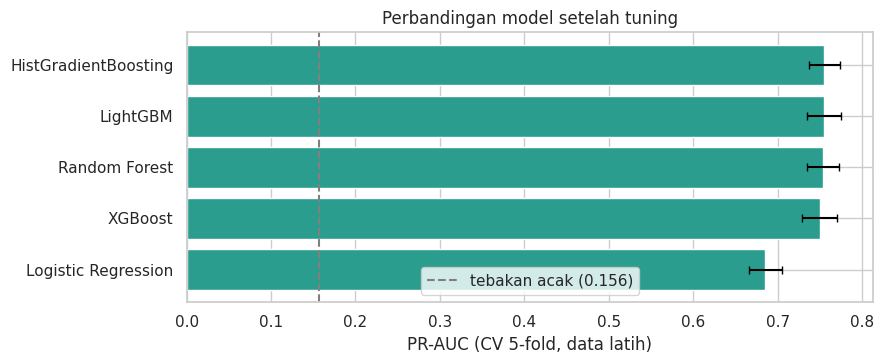

In [17]:
# Hasil pencarian: kandidat terbaik tiap model (berdasarkan PR-AUC CV)
ringkas_cari = pd.DataFrame({
    nama: {"PR-AUC CV (terbaik)": h.loc[0, "pr_auc"], "std antar fold": h.loc[0, "pr_auc_std"],
           "ROC-AUC CV": h.loc[0, "roc_auc"],
           "PR-AUC kandidat terburuk": h["pr_auc"].min(), "rata-rata waktu/kandidat (dtk)": h["detik"].mean()}
    for nama, h in hasil_cari.items()}).T.sort_values("PR-AUC CV (terbaik)", ascending=False)
display(ringkas_cari.round(4))

params_terbaik = {nama: h.loc[0, "params"] for nama, h in hasil_cari.items()}
for nama, p in params_terbaik.items():
    print(f"{nama:22s}", p)

fig, ax = plt.subplots(figsize=(9, 3.8))
urut = ringkas_cari.index[::-1]
ax.barh(urut, ringkas_cari.loc[urut, "PR-AUC CV (terbaik)"], xerr=ringkas_cari.loc[urut, "std antar fold"], capsize=3, color="#2a9d8f")
ax.axvline(y_train.mean(), color="gray", ls="--", label=f"tebakan acak ({y_train.mean():.3f})")
ax.set_xlabel("PR-AUC (CV 5-fold, data latih)"); ax.set_title("Perbandingan model setelah tuning"); ax.legend()
plt.tight_layout(); plt.show()

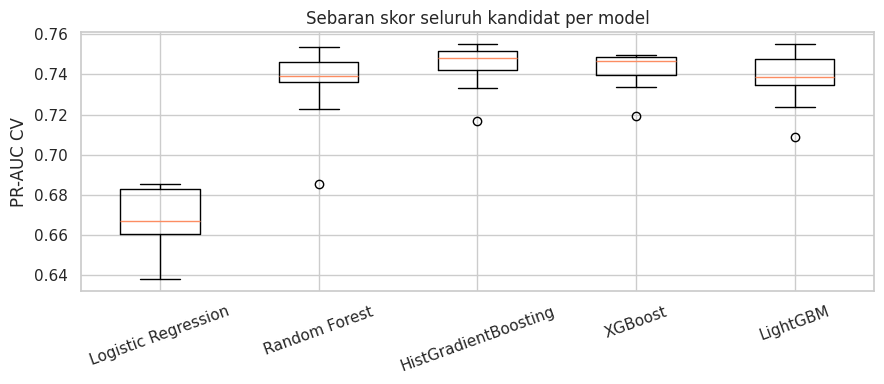

In [18]:
# Seberapa sensitif tiap model terhadap hiperparameter? Sebaran PR-AUC seluruh kandidat
plt.figure(figsize=(9, 4))
data_box = [h["pr_auc"].values for h in hasil_cari.values()]
plt.boxplot(data_box, labels=list(hasil_cari), vert=True); plt.xticks(rotation=20)
plt.ylabel("PR-AUC CV"); plt.title("Sebaran skor seluruh kandidat per model")
plt.tight_layout(); plt.show()

**Interpretasi hasil tuning:**
- **Empat model berbasis pohon praktis setara.** PR-AUC CV berkisar 0,7497 (XGBoost) sampai 0,7551 (HistGradientBoosting). Selisih terbesar 0,005 jauh di bawah simpangan baku antar fold (±0,018–0,021), jadi urutan di antara mereka **tidak bisa dianggap bermakna**.
- **Logistic Regression tertinggal jelas:** 0,6854, sekitar 0,07 di bawah model pohon (hampir 4 kali simpangan baku fold). Ada pola non-linear dan interaksi antar fitur yang tidak tertangkap model linear. Ini membenarkan alasan memakai model pohon.
- **Tuning berpengaruh.** Kandidat terburuk Random Forest 0,686 vs terbaik 0,754; Logistic Regression 0,638 vs 0,685; model boosting 0,709–0,719 vs 0,750–0,755 (lihat boxplot). Memakai hiperparameter bawaan berisiko mendapat hasil di ujung bawah rentang itu.
- **Kelima model memilih konfigurasi tanpa bobot kelas** (`class_weight=None` atau `scale_pos_weight=1`). Ini searah dengan temuan notebook preprocessing 8.6 bahwa bobot kelas tidak memperbaiki kualitas peringkat. Ketidakseimbangan ditangani lewat pemilihan ambang (bagian 5).
- Waktu: Random Forest paling lambat (±10 dtk per kandidat pada 1 CPU), LightGBM tercepat (±1,5 dtk).

# **5. PELATIHAN AKHIR, ENSEMBLE, DAN AMBANG KEPUTUSAN**

Untuk tiap model, parameter terbaik dipakai untuk:
1. **Melatih ulang pada seluruh data latih** (model final), disimpan ke `model_<model>.joblib`.
2. **Membuat prediksi out-of-fold (OOF)** dengan CV yang sama, disimpan ke `oof_<model>.npy`. Setiap baris latih diprediksi oleh model yang **tidak pernah melihat baris itu**, jadi OOF adalah perkiraan jujur performa pada data baru tanpa menyentuh data uji.

OOF dipakai untuk (a) membuat ensemble dan (b) memilih **ambang keputusan** yang memaksimalkan F1. Ambang bawaan 0,5 kurang cocok karena hanya 15,6% sesi yang membeli.

In [19]:
modelku, oof = {}, {}
for nama in MODELS:
    p_model = os.path.join(CKPT_DIR, f"model_{slug(nama)}.joblib")
    p_oof = os.path.join(CKPT_DIR, f"oof_{slug(nama)}.npy")
    t0 = time.time()
    if os.path.exists(p_model) and os.path.exists(p_oof):
        modelku[nama], oof[nama] = joblib.load(p_model), np.load(p_oof)
        print(f"[SKIP] {nama}: model dan OOF dimuat dari checkpoint")
        continue
    if not os.path.exists(p_oof):
        oof[nama] = cross_val_predict(buat_pipeline(nama, params_terbaik[nama]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        simpan_npy(p_oof, oof[nama])
    else:
        oof[nama] = np.load(p_oof)
    modelku[nama] = buat_pipeline(nama, params_terbaik[nama]).fit(X_train, y_train)
    simpan_joblib(p_model, modelku[nama])
    print(f"[SELESAI] {nama}: model final + OOF disimpan ({time.time() - t0:.1f} dtk)")

# Ensemble soft voting: rata-rata probabilitas 3 model dengan PR-AUC CV tertinggi
anggota = list(ringkas_cari.index[:3])
oof["Soft voting (3 terbaik)"] = np.mean([oof[n] for n in anggota], axis=0)
print("\nAnggota ensemble:", anggota)

ambang = {n: ambang_f1_terbaik(y_train, p) for n, p in oof.items()}
tabel_oof = pd.DataFrame({n: metrik(y_train, p, ambang[n]) for n, p in oof.items()}).T.sort_values("PR-AUC", ascending=False)
print("\nPerforma OOF pada data latih (ambang dipilih dari OOF ini):")
display(tabel_oof.round(4))

[SELESAI] Logistic Regression: model final + OOF disimpan (0.9 dtk)
[SELESAI] Random Forest: model final + OOF disimpan (19.0 dtk)
[SELESAI] HistGradientBoosting: model final + OOF disimpan (11.2 dtk)
[SELESAI] XGBoost: model final + OOF disimpan (2.6 dtk)
[SELESAI] LightGBM: model final + OOF disimpan (2.4 dtk)

Anggota ensemble: ['HistGradientBoosting', 'LightGBM', 'Random Forest']

Performa OOF pada data latih (ambang dipilih dari OOF ini):


,PR-AUC,ROC-AUC,ambang,akurasi,balanced_acc,precision,recall,spesifisitas,F1,MCC,Brier
Soft voting (3 terbaik),0.7551,0.9339,0.3480,0.8993,0.8287,0.6623,0.7261,0.9314,0.6927,0.6336,0.0688
HistGradientBoosting,0.7526,0.9323,0.3461,0.8993,0.8274,0.6633,0.7228,0.9320,0.6918,0.6326,0.0693
LightGBM,0.7523,0.9334,0.3219,0.8982,0.8353,0.6530,0.7438,0.9268,0.6955,0.6366,0.0690
Random Forest,0.7518,0.9313,0.3790,0.8986,0.8225,0.6638,0.7117,0.9332,0.6869,0.6270,0.0694
XGBoost,0.7479,0.9313,0.3431,0.8978,0.8302,0.6547,0.7320,0.9285,0.6912,0.6316,0.0694
Logistic Regression,0.6835,0.9124,0.2855,0.8920,0.8182,0.6386,0.7110,0.9255,0.6729,0.6096,0.0770


**Interpretasi pelatihan akhir:**
- **Ambang F1 terbaik** untuk model pohon ada di 0,32–0,38 dan untuk Logistic Regression 0,29, jauh di bawah 0,5. Dengan hanya 15,6% pembeli, ambang 0,5 akan melewatkan banyak pembeli. Ambang ini dipilih dari OOF, bukan dari data uji, dan bisa diganti sesuai biaya (mis. bila menawarkan promo ke non-pembeli murah, turunkan ambang untuk menaikkan recall).
- **Ensemble hampir tidak menambah apa-apa.** PR-AUC OOF soft voting 0,7551 vs HistGradientBoosting 0,7526 (+0,0025), jauh di bawah simpangan baku fold. Model-model pohon belajar pola yang sangat mirip sehingga rata-rata probabilitasnya kurang memberi variasi baru.
- Anggota ensemble adalah tiga model CV tertinggi (HistGradientBoosting, LightGBM, Random Forest); XGBoost tidak masuk.

# **6. EVALUASI PADA DATA UJI**

Data uji dipakai **satu kali** di sini. Semua model, parameter, dan ambang sudah dipilih dari data latih. Model "terbaik" ditentukan dari **PR-AUC CV pada data latih**, bukan dari skor uji, supaya data uji tetap menjadi ukuran yang jujur.

In [20]:
proba_uji = {n: modelku[n].predict_proba(X_test)[:, 1] for n in MODELS}
proba_uji["Soft voting (3 terbaik)"] = np.mean([proba_uji[n] for n in anggota], axis=0)

baris = {"Dummy (selalu tebak tidak beli)": metrik(y_test, dummy.predict_proba(X_test)[:, 1], 0.5)}
for n, p in proba_uji.items():
    baris[n] = metrik(y_test, p, ambang[n])
tabel_uji = pd.DataFrame(baris).T.sort_values("PR-AUC", ascending=False)
display(tabel_uji.round(4))

# Model terbaik menurut CV (bukan menurut data uji)
terbaik_cv = ringkas_cari.index[0]
print(f"Model terbaik menurut CV data latih: {terbaik_cv}")

# Selisih performa latih(OOF) vs uji: indikator overfit atau ketidakcocokan pembagian data
gap = pd.DataFrame({"PR-AUC OOF (latih)": tabel_oof["PR-AUC"], "PR-AUC uji": tabel_uji["PR-AUC"]}).dropna()
gap["selisih (uji - OOF)"] = gap["PR-AUC uji"] - gap["PR-AUC OOF (latih)"]
display(gap.round(4))

,PR-AUC,ROC-AUC,ambang,akurasi,balanced_acc,precision,recall,spesifisitas,F1,MCC,Brier
LightGBM,0.7614,0.9378,0.3219,0.8947,0.8363,0.6392,0.7513,0.9213,0.6907,0.6308,0.0675
Soft voting (3 terbaik),0.7593,0.9364,0.3480,0.8984,0.8300,0.6580,0.7304,0.9296,0.6923,0.6329,0.0679
XGBoost,0.7562,0.9386,0.3431,0.8947,0.8289,0.6437,0.7330,0.9247,0.6854,0.6244,0.0677
HistGradientBoosting,0.7560,0.9361,0.3461,0.9009,0.8389,0.6620,0.7487,0.9291,0.7027,0.6452,0.0683
Random Forest,0.7527,0.9319,0.3790,0.8984,0.8182,0.6667,0.7016,0.9349,0.6837,0.6235,0.0689
Logistic Regression,0.6961,0.9219,0.2855,0.8890,0.8212,0.6259,0.7225,0.9199,0.6707,0.6066,0.0744
Dummy (selalu tebak tidak beli),0.1565,0.5000,0.5000,0.8435,0.5000,0.0000,0.0000,1.0000,0.0000,0.0000,0.1320


Model terbaik menurut CV data latih: HistGradientBoosting


,PR-AUC OOF (latih),PR-AUC uji,selisih (uji - OOF)
HistGradientBoosting,0.7526,0.7560,0.0033
LightGBM,0.7523,0.7614,0.0091
Logistic Regression,0.6835,0.6961,0.0126
Random Forest,0.7518,0.7527,0.0010
Soft voting (3 terbaik),0.7551,0.7593,0.0041
XGBoost,0.7479,0.7562,0.0083


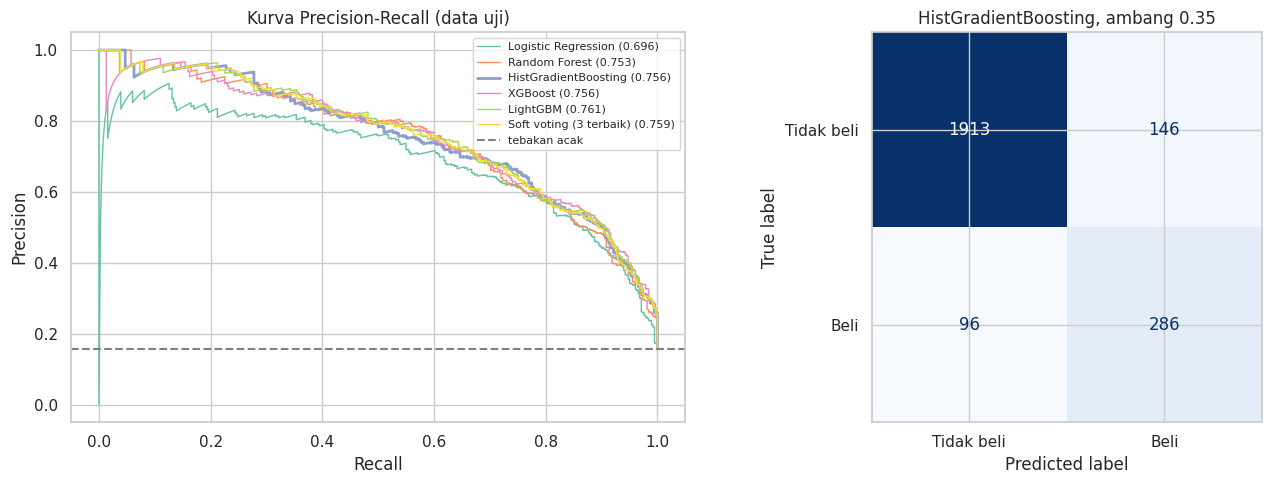

Dari 382 sesi pembeli di data uji, 286 terdeteksi (recall 74.9%); 146 sesi bukan pembeli ikut ditandai.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Kurva Precision-Recall
for n, p in proba_uji.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, label=f"{n} ({average_precision_score(y_test, p):.3f})", lw=2 if n == terbaik_cv else 1)
axes[0].axhline(y_test.mean(), color="gray", ls="--", label="tebakan acak")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Kurva Precision-Recall (data uji)"); axes[0].legend(fontsize=8)

# Matriks konfusi model terbaik pada ambang dari OOF
pred = (proba_uji[terbaik_cv] >= ambang[terbaik_cv]).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Tidak beli", "Beli"]).plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"{terbaik_cv}, ambang {ambang[terbaik_cv]:.2f}")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, pred)
print(f"Dari {cm[1].sum()} sesi pembeli di data uji, {cm[1, 1]} terdeteksi (recall {cm[1, 1] / cm[1].sum():.1%}); {cm[0, 1]} sesi bukan pembeli ikut ditandai.")

**Interpretasi evaluasi data uji:**
- Semua model jauh di atas tebakan acak (PR-AUC 0,157): 0,70 (Logistic Regression) sampai 0,76 (model pohon).
- **Model terbaik menurut CV adalah HistGradientBoosting**: PR-AUC uji 0,7560; pada ambang 0,35 precision 0,662, recall 0,749, F1 0,703. Dari 382 sesi pembeli di data uji, 286 terdeteksi dan 146 sesi bukan pembeli ikut ditandai.
- LightGBM memiliki skor uji tertinggi (0,7614) dan soft voting 0,7592, tetapi selisihnya dengan HistGradientBoosting (≤ 0,006) jauh di bawah simpangan baku CV. Memilih model berdasarkan skor uji berarti memakai data uji untuk seleksi, jadi pilihan tetap mengikuti CV.
- **Tidak ada tanda overfit:** selisih skor uji dikurangi OOF berkisar +0,001 sampai +0,013 (uji sedikit lebih tinggi, kemungkinan kebetulan pada pembagian ini).
- Logistic Regression tertinggal sekitar 0,06 dari model terbaik, konsisten dengan hasil CV.

## 6.1 Laporan lengkap model terbaik dan ketidakpastiannya

Matriks konfusi, laporan per kelas, dan **selang kepercayaan 95%** (bootstrap atas data uji, tanpa melatih ulang). Data uji hanya memuat ±380 pembeli, sehingga setiap skor di atas hanyalah perkiraan; selang ini menunjukkan seberapa jauh angka itu bisa bergeser.

In [22]:
p_b = proba_uji[terbaik_cv]
thr = ambang[terbaik_cv]
yv = y_test.values
pred_b = (p_b >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(yv, pred_b).ravel()
n = len(yv)

print(f"Model: {terbaik_cv} | ambang {thr:.3f} (dipilih dari OOF data latih)\n")
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["Aktual: tidak beli", "Aktual: beli"],
                     columns=["Prediksi: tidak beli", "Prediksi: beli"]))
print(classification_report(yv, pred_b, target_names=["tidak beli", "beli"], digits=3))

print(f"Akurasi {(tp + tn) / n:.1%}, padahal menebak semua 'tidak beli' sudah {1 - yv.mean():.1%}. "
      f"Kemampuan nyata ada pada pembeli: recall {tp / (tp + fn):.1%}, precision {tp / (tp + fp):.1%}.")

# Selang kepercayaan 95% dengan bootstrap (resampling baris uji; prediksi tetap)
rng = np.random.default_rng(RANDOM_STATE)
cuplikan = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    cuplikan.append(metrik(yv[idx], p_b[idx], thr))
boot = pd.DataFrame(cuplikan)
kolom_ci = ["PR-AUC", "ROC-AUC", "akurasi", "balanced_acc", "precision", "recall", "F1", "MCC", "Brier"]
nilai_uji = metrik(yv, p_b, thr)
ci = pd.DataFrame({"nilai uji": [nilai_uji[k] for k in kolom_ci],
                   "batas bawah 95%": boot[kolom_ci].quantile(0.025).values,
                   "batas atas 95%": boot[kolom_ci].quantile(0.975).values}, index=kolom_ci)
display(ci.round(3))

Model: HistGradientBoosting | ambang 0.346 (dipilih dari OOF data latih)



,Prediksi: tidak beli,Prediksi: beli
Aktual: tidak beli,1913,146
Aktual: beli,96,286


              precision    recall  f1-score   support

  tidak beli      0.952     0.929     0.941      2059
        beli      0.662     0.749     0.703       382

    accuracy                          0.901      2441
   macro avg      0.807     0.839     0.822      2441
weighted avg      0.907     0.901     0.903      2441

Akurasi 90.1%, padahal menebak semua 'tidak beli' sudah 84.4%. Kemampuan nyata ada pada pembeli: recall 74.9%, precision 66.2%.


,nilai uji,batas bawah 95%,batas atas 95%
PR-AUC,0.756,0.715,0.799
ROC-AUC,0.936,0.924,0.948
akurasi,0.901,0.889,0.913
balanced_acc,0.839,0.816,0.862
precision,0.662,0.621,0.708
recall,0.749,0.703,0.793
F1,0.703,0.668,0.738
MCC,0.645,0.605,0.687
Brier,0.068,0.062,0.075


**Interpretasi laporan lengkap:**
- **Matriks konfusi:** 1.913 bukan-pembeli dikenali (TN), 146 salah ditandai (FP), 96 pembeli terlewat (FN), 286 pembeli terdeteksi (TP).
- **Akurasi 90,1% hanya 5,7 poin di atas tebakan "selalu tidak beli" (84,4%)**, padahal model ini jauh lebih berguna. Akurasi didominasi kelas mayoritas, jadi tidak cocok sebagai ukuran utama. Kemampuan nyata ada di kelas pembeli: precision 0,662, recall 0,749, F1 0,703. Kelas "tidak beli" dikenali dengan spesifisitas 0,929.
- **Balanced accuracy 0,839 dan MCC 0,645** (0 = acak) adalah satu angka yang tidak tertipu proporsi kelas. Keduanya konsisten dengan gambaran di atas: model cukup baik, belum sempurna.
- **Brier score 0,068** dibanding 0,132 pada tebakan prior: probabilitasnya jauh lebih informatif. Ini belum membuktikan probabilitasnya terkalibrasi (belum diperiksa).
- **Selang kepercayaan 95%:** PR-AUC 0,715–0,799 dan recall 0,703–0,793. Lebarnya ±0,04 karena data uji hanya memuat 382 pembeli. Selisih antar model pohon pada data uji (≤ 0,009) jauh lebih kecil dari lebar selang ini, jadi model-model itu tidak bisa dibedakan. PR-AUC Logistic Regression (0,696) berada di bawah batas bawah selang HistGradientBoosting, sehingga tertinggalnya tampak nyata (perbandingan kasar; dua selang tidak dihitung berpasangan).
- Selang ini hanya mencerminkan variasi sampel data uji, bukan variasi akibat pelatihan ulang atau pembagian data yang lain.

## 6.2 Sensitivitas ambang keputusan

Ambang menentukan **pertukaran** antara precision dan recall. Tabel dan grafik di bawah memakai prediksi OOF **data latih** (bukan data uji), karena inilah dasar pemilihan ambang. Bila intervensi murah, turunkan ambang untuk menjaring lebih banyak pembeli; bila mahal, naikkan.

OOF data latih, model HistGradientBoosting. Ambang terpilih = 0.346


,ditandai_beli,precision,recall,F1,akurasi,pembeli_terlewat,salah_tandai
ambang,,,,,,,
0.100,3044,0.449,0.896,0.599,0.812,158,1676
0.200,2221,0.556,0.809,0.659,0.869,291,986
0.300,1806,0.632,0.748,0.685,0.893,384,664
0.346,1664,0.663,0.723,0.692,0.899,423,561
0.400,1506,0.684,0.675,0.679,0.900,496,476
0.500,1270,0.730,0.607,0.663,0.904,599,343
0.600,984,0.785,0.506,0.615,0.901,754,212
0.700,699,0.850,0.389,0.534,0.894,932,105


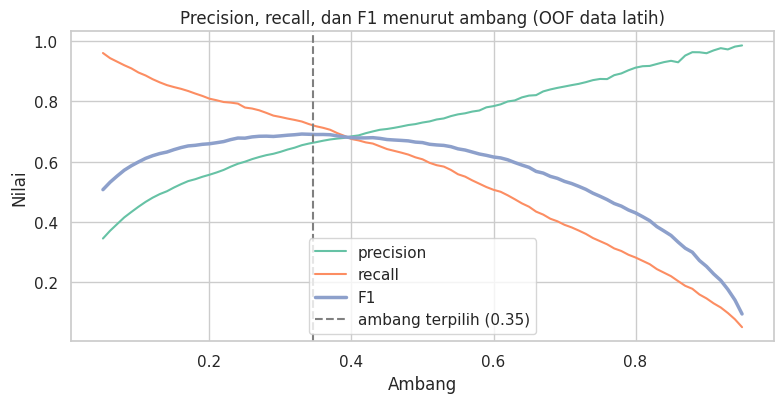

In [23]:
p_oof = oof[terbaik_cv]
daftar = sorted(set([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, round(float(ambang[terbaik_cv]), 3)]))
baris_t = []
for t in daftar:
    pr_ = (p_oof >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_train, pr_, labels=[0, 1]).ravel()
    baris_t.append({"ambang": t, "ditandai_beli": int(pr_.sum()),
                    "precision": precision_score(y_train, pr_, zero_division=0), "recall": recall_score(y_train, pr_),
                    "F1": f1_score(y_train, pr_), "akurasi": accuracy_score(y_train, pr_),
                    "pembeli_terlewat": int(fn_), "salah_tandai": int(fp_)})
tabel_ambang = pd.DataFrame(baris_t).set_index("ambang")
print(f"OOF data latih, model {terbaik_cv}. Ambang terpilih = {ambang[terbaik_cv]:.3f}")
display(tabel_ambang.round(3))

tt = np.linspace(0.05, 0.95, 91)
P = [precision_score(y_train, (p_oof >= t).astype(int), zero_division=0) for t in tt]
R = [recall_score(y_train, (p_oof >= t).astype(int)) for t in tt]
F = [f1_score(y_train, (p_oof >= t).astype(int)) for t in tt]
plt.figure(figsize=(8, 4.2))
plt.plot(tt, P, label="precision"); plt.plot(tt, R, label="recall"); plt.plot(tt, F, label="F1", lw=2.5)
plt.axvline(ambang[terbaik_cv], color="gray", ls="--", label=f"ambang terpilih ({ambang[terbaik_cv]:.2f})")
plt.xlabel("Ambang"); plt.ylabel("Nilai"); plt.title("Precision, recall, dan F1 menurut ambang (OOF data latih)")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretasi sensitivitas ambang:**
- **Pertukaran precision dan recall terlihat jelas.** Pada ambang 0,1 recall 0,896 tetapi precision hanya 0,449 (3.044 sesi ditandai, 1.676 di antaranya salah). Pada ambang 0,7 precision 0,850 tetapi recall 0,389. Ambang terpilih 0,346 memberi precision 0,663 dan recall 0,723 pada OOF.
- **F1 relatif datar di sekitar 0,3–0,4** (0,685; 0,692; 0,679), jadi memilih ambang ±0,35 bukan keputusan yang rapuh. Bergeser sedikit tidak mengubah hasil banyak.
- **Akurasi memberi sinyal yang keliru.** Akurasi di ambang 0,5 (0,904) sedikit lebih tinggi daripada di ambang terpilih (0,899), padahal ambang 0,5 melewatkan 176 pembeli lebih banyak (599 vs 423). Memilih ambang berdasarkan akurasi akan merugikan pada data yang tidak seimbang.
- Pemilihan akhir sebaiknya mempertimbangkan biaya: bila menawarkan promo ke non-pembeli murah, turunkan ambang; bila mahal, naikkan.

# **7. UJI TANPA `PAGEVALUES` DAN INTERPRETASI MODEL**

`PageValues` adalah nilai rata-rata halaman yang dikunjungi sebelum transaksi, dan di notebook preprocessing terbukti sangat dominan sekaligus **berpotensi bocor** (nilainya dihitung dari hasil transaksi). Karena itu setiap model juga dinilai **tanpa fitur ini**, memakai hiperparameter terbaik yang sama (tanpa mencari ulang).

In [24]:
abl = {}
for nama in MODELS:
    p_abl = os.path.join(CKPT_DIR, f"ablasi_{slug(nama)}.json")
    if os.path.exists(p_abl):
        abl[nama] = muat_json(p_abl); print(f"[SKIP] ablasi {nama}"); continue
    r = cross_validate(buat_pipeline(nama, params_terbaik[nama], drop_pagevalues=True), X_train, y_train, cv=cv,
                       scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    abl[nama] = {"pr_auc": float(r["test_pr_auc"].mean()), "std": float(r["test_pr_auc"].std()), "roc_auc": float(r["test_roc_auc"].mean())}
    simpan_json(p_abl, abl[nama]); print(f"[SELESAI] ablasi {nama}")

tabel_abl = pd.DataFrame({
    "PR-AUC dengan PageValues": ringkas_cari["PR-AUC CV (terbaik)"],
    "PR-AUC tanpa PageValues": pd.Series({n: v["pr_auc"] for n, v in abl.items()}),
    "ROC-AUC tanpa PageValues": pd.Series({n: v["roc_auc"] for n, v in abl.items()}),
})
tabel_abl["penurunan"] = tabel_abl["PR-AUC dengan PageValues"] - tabel_abl["PR-AUC tanpa PageValues"]
display(tabel_abl.sort_values("PR-AUC tanpa PageValues", ascending=False).round(4))
print(f"Pembanding tebakan acak: {y_train.mean():.3f}")

[SELESAI] ablasi Logistic Regression
[SELESAI] ablasi Random Forest
[SELESAI] ablasi HistGradientBoosting
[SELESAI] ablasi XGBoost
[SELESAI] ablasi LightGBM


,PR-AUC dengan PageValues,PR-AUC tanpa PageValues,ROC-AUC tanpa PageValues,penurunan
LightGBM,0.7549,0.3860,0.7804,0.3689
HistGradientBoosting,0.7551,0.3854,0.7782,0.3697
Random Forest,0.7536,0.3755,0.7731,0.3781
XGBoost,0.7497,0.3713,0.7763,0.3784
Logistic Regression,0.6854,0.3416,0.7497,0.3438


Pembanding tebakan acak: 0.156


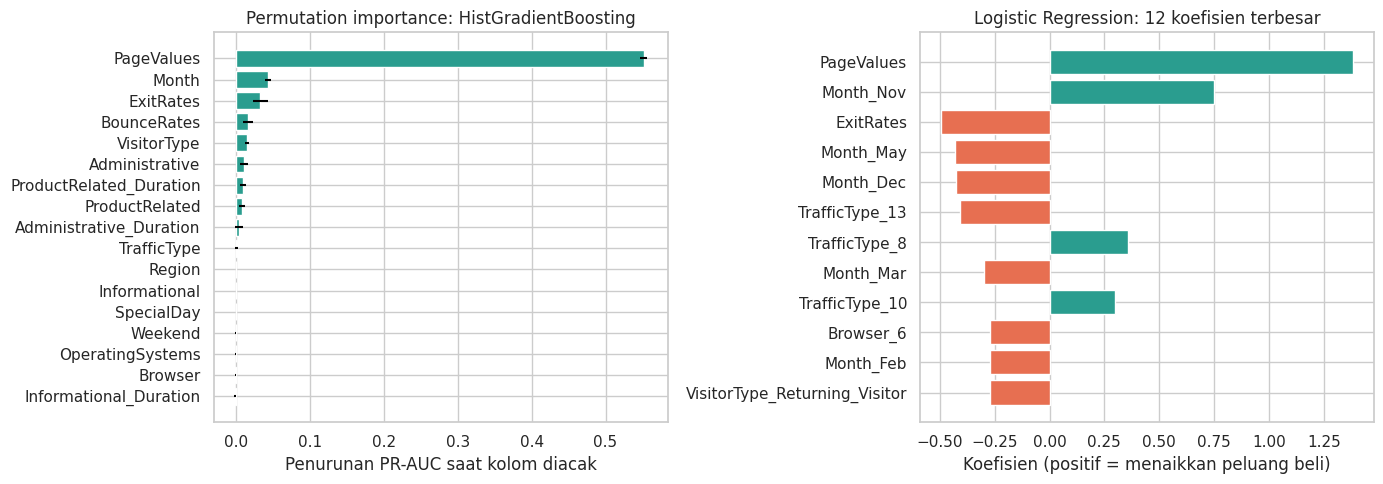

5 fitur teratas (permutation importance):
PageValues     0.5514
Month          0.0435
ExitRates      0.0332
BounceRates    0.0159
VisitorType    0.0152


In [25]:
# (a) Permutation importance pada data uji untuk model terbaik menurut CV:
#     seberapa turun PR-AUC bila satu kolom asli diacak. Dihitung pada kolom MENTAH, jadi mudah dibaca.
pi = permutation_importance(modelku[terbaik_cv], X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp_std = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(imp.index, imp.values, xerr=imp_std.values, color="#2a9d8f")
axes[0].set_title(f"Permutation importance: {terbaik_cv}"); axes[0].set_xlabel("Penurunan PR-AUC saat kolom diacak")

# (b) Koefisien Logistic Regression terbaik (arah pengaruh, pada skala fitur terstandar)
lr = modelku["Logistic Regression"]
nama_fitur = lr.named_steps["prep"].get_feature_names_out()
koef = pd.Series(lr.named_steps["clf"].coef_[0], index=nama_fitur)
top = koef.reindex(koef.abs().sort_values(ascending=False).index[:12])[::-1]
axes[1].barh(top.index, top.values, color=["#2a9d8f" if v > 0 else "#e76f51" for v in top.values])
axes[1].set_title("Logistic Regression: 12 koefisien terbesar"); axes[1].set_xlabel("Koefisien (positif = menaikkan peluang beli)")
plt.tight_layout(); plt.show()

print("5 fitur teratas (permutation importance):")
print(imp[::-1].head(5).round(4).to_string())

**Interpretasi uji tanpa `PageValues` dan pentingnya fitur:**
- **Tanpa `PageValues`, PR-AUC turun hampir separuh**, dari ≈ 0,75 menjadi 0,34–0,39 (turun 0,34–0,38). Model masih sekitar 2,2–2,5 kali lebih baik dari tebakan acak (0,156), jadi ada sinyal dari perilaku penjelajahan, tetapi jauh lebih lemah.
- Urutan model tanpa `PageValues` serupa: LightGBM 0,386, HistGradientBoosting 0,385, Random Forest 0,376, XGBoost 0,371, Logistic Regression 0,342. Selisih antar model pohon kecil (≤ 0,015). Jarak model pohon dengan Logistic Regression mengecil menjadi ≈ 0,04; sebagian keunggulan model pohon tampaknya terkait `PageValues` (dugaan, belum diuji langsung).
- **Permutation importance** (HistGradientBoosting, data uji): `PageValues` menurunkan PR-AUC 0,551 saat diacak, jauh di atas `Month` (0,044), `ExitRates` (0,033), `BounceRates` (0,016), dan `VisitorType` (0,015). Fitur lain berkontribusi kecil.
- **Catatan penggunaan:** `PageValues` dihitung dari data transaksi sehingga berpotensi bocor bila model dipakai memprediksi sesi yang sedang berjalan. Varian **dengan** `PageValues` cocok untuk analisis dan perbandingan; untuk prediksi saat sesi berlangsung, patokan realistisnya adalah varian **tanpa** `PageValues` (PR-AUC ≈ 0,39).

# **8. MENYIMPAN HASIL DAN KESIMPULAN**

In [26]:
hasil_dir = os.path.join(CKPT_DIR, "hasil")
os.makedirs(hasil_dir, exist_ok=True)

tabel_uji.round(4).to_csv(os.path.join(hasil_dir, "hasil_uji.csv"))
ringkas_cari.round(4).to_csv(os.path.join(hasil_dir, "hasil_cv_tuning.csv"))
tabel_abl.round(4).to_csv(os.path.join(hasil_dir, "hasil_tanpa_pagevalues.csv"))
simpan_json(os.path.join(hasil_dir, "parameter_terbaik.json"), {n: bersihkan(p) for n, p in params_terbaik.items()})
simpan_joblib(os.path.join(hasil_dir, "model_terbaik.joblib"),
              {"nama": terbaik_cv, "model": modelku[terbaik_cv], "ambang": ambang[terbaik_cv]})

print("Isi folder hasil:", sorted(os.listdir(hasil_dir)))
print("\nDaftar seluruh checkpoint:")
display(status_checkpoint())

# Salinan zip untuk diunduh (di Colab). Checkpoint asli tetap aman di Drive.
with zipfile.ZipFile("hasil_modelling.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir(hasil_dir):
        z.write(os.path.join(hasil_dir, f), arcname=f"hasil_modelling/{f}")
try:
    from google.colab import files
    files.download("hasil_modelling.zip")
except ImportError:
    print("Bukan Google Colab: unduhan dilewati. Zip ada di hasil_modelling.zip")

Isi folder hasil: ['hasil_cv_tuning.csv', 'hasil_tanpa_pagevalues.csv', 'hasil_uji.csv', 'model_terbaik.joblib', 'parameter_terbaik.json']

Daftar seluruh checkpoint:


,file,ukuran_KB
0,ablasi_histgradientboosting.json,0.1
1,ablasi_lightgbm.json,0.1
2,ablasi_logistic_regression.json,0.1
3,ablasi_random_forest.json,0.1
4,ablasi_xgboost.json,0.1
5,cari_histgradientboosting.jsonl,4.1
6,cari_lightgbm.jsonl,4.5
7,cari_logistic_regression.jsonl,2.8
8,cari_random_forest.jsonl,3.5
9,cari_xgboost.jsonl,4.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan

| Model | PR-AUC CV (latih) | PR-AUC uji | Catatan |
|---|---|---|---|
| Dummy (prior) | – | 0,157 | Batas bawah |
| Logistic Regression | 0,685 | 0,696 | Dapat dibaca, tertinggal ±0,06 |
| Random Forest | 0,754 | 0,753 | Paling lambat dilatih |
| **HistGradientBoosting** | **0,755** | **0,756** | **Terbaik menurut CV, dipilih** |
| XGBoost | 0,750 | 0,756 | Setara |
| LightGBM | 0,755 | 0,761 | Setara dan tercepat |
| Soft voting (3 terbaik) | 0,755 (OOF) | 0,759 | Tidak menambah nilai berarti |

**Rekomendasi**
1. **Model utama: HistGradientBoosting** (terbaik menurut CV). XGBoost, LightGBM, dan Random Forest tidak bisa dibedakan darinya secara statistik; bila kecepatan latih penting, LightGBM adalah alternatif yang setara. Ensemble tidak diperlukan.
2. **Ambang keputusan ±0,35** (dari OOF) memberi recall ≈ 0,75 dan precision ≈ 0,66. Sesuaikan dengan biaya intervensi bisnis. Akurasi (90,1%) tidak dipakai sebagai ukuran utama karena tebakan "selalu tidak beli" sudah 84,4%.
3. Untuk prediksi pada sesi yang sedang berjalan, gunakan varian **tanpa `PageValues`** dan harapkan PR-AUC ≈ 0,39, bukan 0,75.

**Keterbatasan**
- Hanya satu pembagian latih/uji; data uji hanya memuat 382 pembeli, sehingga selisih kecil antar model tidak bermakna. Selang kepercayaan 95% PR-AUC model terbaik adalah 0,715–0,799 (bagian 6.1).
- `N_ITER = 12` termasuk kecil; naikkan (mis. 30) bila waktu Colab cukup. Mengubah `N_ITER` membuat folder checkpoint baru, sehingga pencarian dimulai dari awal.
- Pembagian dilakukan acak, bukan berdasarkan waktu. Performa pada bulan yang belum pernah dilihat model belum diuji.
- Probabilitas belum dikalibrasi; gunakan sebagai peringkat atau lewat ambang, bukan sebagai peluang absolut.

**Langkah lanjut:** kalibrasi probabilitas, validasi per bulan, pemilihan ambang berbasis biaya, dan SHAP untuk penjelasan per sesi.